# Quantum phase estimation

Phase estimation reads the eigenphase of a unitary into a register of counting qubits, through controlled powers of the
unitary and an inverse quantum Fourier transform. It is the core of Shor's algorithm and of many chemistry methods.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:9e791f',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Reading the phase of a T gate

T|1⟩ = e^{2πi·(1/8)}|1⟩. With three counting qubits the phase 1/8 is exact in binary (0.001), so every shot reads 001.

In [2]:
def qpe(phase, counting):
    """Estimate e^{2 pi i phase} of a phase gate on |1>, with `counting` counting qubits (target = last qubit)."""
    t = counting
    lines = [f"x q[{t}]", *(f"h q[{k}]" for k in range(t))]
    for k in range(t):                                   # controlled U^(2^k)
        lines.append(f"cu1({2 * np.pi * phase * 2 ** k}) q[{k}],q[{t}]")
    for k in range(t // 2):                              # inverse QFT on the counting register
        lines.append(f"swap q[{k}],q[{t - 1 - k}]")
    for j in range(t):
        for m in range(j):
            lines.append(f"cu1({-np.pi / 2 ** (j - m)}) q[{m}],q[{j}]")
        lines.append(f"h q[{j}]")
    return HEADER + f"qreg q[{t + 1}];\ncreg c[{t}];\n" + "".join(f"{l};\n" for l in lines) + \
        "".join(f"measure q[{k}] -> c[{k}];\n" for k in range(t))

r = run("quantinuum_helios", qpe(1 / 8, 3), shots=2000)
print(r["result"]["counts"], "-> phase", int(max(r["result"]["counts"], key=r["result"]["counts"].get), 2) / 8)

{'001': 2000} -> phase 0.125


## 2. A phase that is not a binary fraction

For φ = 0.3 the estimate concentrates on the nearest values k/2ᵗ. More counting qubits sharpen it.

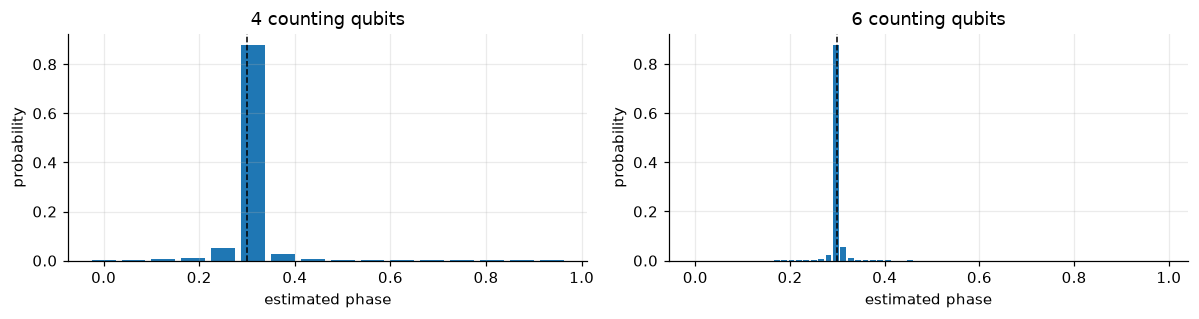

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, t in zip(axes, (4, 6)):
    counts = run("quantinuum_helios", qpe(0.3, t), shots=20000)["result"]["counts"]
    xs = sorted(counts, key=lambda k: int(k, 2))
    ax.bar([int(k, 2) / 2 ** t for k in xs], [counts[k] / 20000 for k in xs], width=0.8 / 2 ** t)
    ax.axvline(0.3, color="black", ls="--", lw=1)
    ax.set_title(f"{t} counting qubits"); ax.set_xlabel("estimated phase"); ax.set_ylabel("probability")
plt.tight_layout(); plt.show()

## 3. Phase estimation under device noise

The probability of reading the right answer (001 for T) on each twin. The controlled phases and the inverse QFT are deep enough for device noise to show.

In [4]:
rows = []
for b in ALL_BACKENDS:
    r = run(b, qpe(1 / 8, 3), shots=20000, noise=True, routing=True)
    rows.append({"twin": NAMES[b], "P(correct phase)": success(r, ["001"]),
                 "native 2Q gates": r["compilation"]["native_two_qubit_count"]})
pd.DataFrame(rows).set_index("twin").round(4)

,P(correct phase),native 2Q gates
twin,,
Helios,0.9883,15
Forte,0.9184,15
Ankaa-3,0.6686,21
Emerald,0.7638,21
Heron r3,0.9670,21
Nighthawk,0.9338,21
Willow,0.9212,21


## 4. More precision, more noise

Extra counting qubits give more precision but a deeper circuit. Noise spreads the probability: the best estimate is read less often on the noisier twin, even while it keeps improving.

In [5]:
rows = []
for t in (3, 4, 5, 6):
    row = {"counting qubits": t}
    for b in ("quantinuum_helios", "iqm_emerald"):
        c = run(b, qpe(0.3, t), shots=20000, noise=True, routing=True)["result"]["counts"]
        best = int(max(c, key=c.get), 2) / 2 ** t
        row[f"{NAMES[b]} estimate"] = best
        row[f"{NAMES[b]} P(estimate)"] = round(max(c.values()) / 20000, 3)
    rows.append(row)
pd.DataFrame(rows).set_index("counting qubits")

,Helios estimate,Helios P(estimate),Emerald estimate,Emerald P(estimate)
counting qubits,,,,
3,0.250000,0.567,0.250000,0.462
4,0.312500,0.858,0.312500,0.514
5,0.312500,0.557,0.312500,0.300
6,0.296875,0.838,0.296875,0.305


## Takeaways

- Phase estimation runs end to end on every twin, including its controlled phases and inverse QFT.
- Precision costs depth, and depth costs fidelity: the twins show where the trade-off turns.